# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**Lucas Moyano**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


Voy a usar una entrevista a Kevin Vallejos, peleador de UFC, hecha por el canal SPORT.

In [86]:
# URL de la entrevista en SPORT
url = "https://www.sport.es/es/noticias/ufc/kevin-vallejos-perla-argentina-ufc-120143182"

In [87]:
# Instalar librerias
! pip install requests beautifulsoup4 html5lib

In [88]:
!pip install wordcloud

In [89]:
import requests
from bs4 import BeautifulSoup

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.tokenize import sent_tokenize

nltk.download('stopwords')
nltk.download('punkt_tab')

from wordcloud import WordCloud
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import sys
import pandas as pd

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [90]:
# Realizar la solicitud HTTP
response = requests.get(url)
try:
  response.raise_for_status()
  response.raise_for_status()

except requests.exceptions.RequestException as e:
  print(f"Error al consultar la URL {e}")

Error al consultar la URL 406 Client Error: WAF Forbidden for url: https://www.sport.es/es/noticias/ufc/kevin-vallejos-perla-argentina-ufc-120143182


Como el sitio está protegido en este caso, uso un User-Agent para simular ser un usuario y tener acceso al contenido de la página.

In [91]:
# Definir un User-Agent
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept-Language": "es-ES,es;q=0.9,en;q=0.8",
}

try:
  response = requests.get(url, headers=headers)
  response.raise_for_status()

except requests.exceptions.RequestException as e:
  print(f"Error al consultar la URL {e}")
except Exception as e:
  print(f"Ocurrió un error inesperado: {e}")

In [92]:
# Armar la sopa
soup = BeautifulSoup(response.content, "html5lib")
print(soup)

<!DOCTYPE html>
<html lang="es"><head><meta charset="utf-8"/><meta content="width=device-width, initial-scale=1" name="viewport"/><meta content="294,67,7,179,187,68,31,234,225,10,30" name="pimec:tags"/><meta content="53,520,485,546,324" name="iab:tags"/><meta content="1" name="themost"/><meta content="158509027015217" property="fb:app_id"/><meta content="17753392534" property="fb:pages"/><meta content="text/html; charset=utf-8" http-equiv="Content-Type"/><meta content="BBT bCube NX" name="generator"/><meta content="Diario Sport" name="publisher"/><meta content="Nil Jaimejuan" name="author"/><meta content="article" property="og:type"/><meta content="Kevin Vallejos, la perla argentina de UFC: 'Mi sueño es ser perfecto como Topuria y el campeón del pueblo como Oliveira'" property="og:title"/><meta content="'El Chino' Vallejos es, a sus 23 años, uno de los peleadores más prometedores de la UFC y apunta a dominar la división del peso pluma en un futuro" property="og:description"/><meta cont

In [93]:
# Extraer el título
titulo = soup.find("h1").get_text()
print(titulo)

Kevin Vallejos, la perla argentina de UFC: "Mi sueño es ser perfecto como Topuria y el campeón del pueblo como Oliveira"


In [94]:
# Extraer el texto plano de los párrafos iterando y agregar el título extraído
elementos_p = soup.find_all("p", class_="ft-text")

texto = []
texto.append(titulo)
for elemento in elementos_p:
  elemento = elemento.get_text()
  texto.append(elemento)

print(texto)

['Kevin Vallejos, la perla argentina de UFC: "Mi sueño es ser perfecto como Topuria y el campeón del pueblo como Oliveira"', "Es argentino, lo apodan el 'Chino' y, a sus 23 años, ya es uno de los diamantes en bruto de la UFC. Kevin Vallejos (Mar del Plata, Buenos Aires, 2001) disputa este sábado 2 de agosto su segundo combate dentro de la mejor liga del mundo de artes marciales mixtas. Su debut y carta de presentación ante el gran público fue excelente: un KO en el primer asalto, marca de la casa, dejó a Seung Woo Choi dormido en la lona. Un nuevo guerrero albiceleste irrumpía en la división del peso pluma de la UFC, una de las más talentosas de la compañía y en la que nuestro protagonista está destinado a grandes cosas.", "En el primer día de la 'Fight Week' para su pelea ante Danny Silva, rival con un récord profesional de 10-1 y de orígenes mexicanos, Vallejos atiende a SPORT unos minutos para hablar sobre su próximo compromiso, su estado de forma, su parecido a Ilia Topuria dentro 

In [95]:
# Limpiar la lista sacando los espacios extra y los elementos vacíos
texto_limpio = [texto.strip() for texto in texto if texto.strip() != ""]

# Unir todos los elementos limpios
texto_final = " ".join(texto_limpio)

# Sacar todos los espacios extra en medio de las oraciones
texto_final = " ".join(texto_final.split())

texto_final

'Kevin Vallejos, la perla argentina de UFC: "Mi sueño es ser perfecto como Topuria y el campeón del pueblo como Oliveira" Es argentino, lo apodan el \'Chino\' y, a sus 23 años, ya es uno de los diamantes en bruto de la UFC. Kevin Vallejos (Mar del Plata, Buenos Aires, 2001) disputa este sábado 2 de agosto su segundo combate dentro de la mejor liga del mundo de artes marciales mixtas. Su debut y carta de presentación ante el gran público fue excelente: un KO en el primer asalto, marca de la casa, dejó a Seung Woo Choi dormido en la lona. Un nuevo guerrero albiceleste irrumpía en la división del peso pluma de la UFC, una de las más talentosas de la compañía y en la que nuestro protagonista está destinado a grandes cosas. En el primer día de la \'Fight Week\' para su pelea ante Danny Silva, rival con un récord profesional de 10-1 y de orígenes mexicanos, Vallejos atiende a SPORT unos minutos para hablar sobre su próximo compromiso, su estado de forma, su parecido a Ilia Topuria dentro de 

## 2- Preprocesamiento

### 2.1 Muestra las stop words que tenga tu texto.

In [96]:
# Tokenizacion
tokens = word_tokenize(texto_final.lower(), language='spanish')

# Filtrar  las stopwords
lista_stopwords = set(stopwords.words('spanish'))
stopword_texto = [p for p in tokens if p in lista_stopwords]
stopwords_unicas = sorted(set(stopword_texto))
print(stopwords_unicas)

['a', 'al', 'algo', 'algunos', 'ante', 'antes', 'como', 'con', 'contra', 'cuando', 'de', 'del', 'desde', 'donde', 'e', 'el', 'ellos', 'en', 'entre', 'era', 'eres', 'es', 'esa', 'esas', 'ese', 'eso', 'esos', 'esta', 'estaba', 'estaban', 'estado', 'estados', 'estamos', 'estando', 'estar', 'este', 'esto', 'estoy', 'estuve', 'está', 'están', 'fue', 'fuera', 'fueron', 'fui', 'ha', 'habrá', 'había', 'has', 'hasta', 'hay', 'haya', 'he', 'la', 'las', 'le', 'lo', 'los', 'me', 'mi', 'mis', 'mucho', 'muchos', 'muy', 'más', 'mí', 'mía', 'mío', 'nada', 'ni', 'no', 'nos', 'nosotros', 'nuestro', 'o', 'otra', 'otras', 'otro', 'otros', 'para', 'pero', 'poco', 'por', 'porque', 'que', 'quien', 'qué', 'se', 'sea', 'sentido', 'será', 'sería', 'sin', 'sobre', 'son', 'soy', 'su', 'sus', 'sí', 'también', 'tanto', 'te', 'tenemos', 'tengo', 'tenía', 'tenían', 'tiene', 'tienes', 'todo', 'todos', 'tu', 'tuve', 'tú', 'un', 'una', 'uno', 'unos', 'y', 'ya', 'yo', 'él']


### 2.2 Quita las stop-words, caracteres extraños del texto. Utiliza el texto restante para crear una nube de palabras. Usa la biblioteca worldcloud de python.

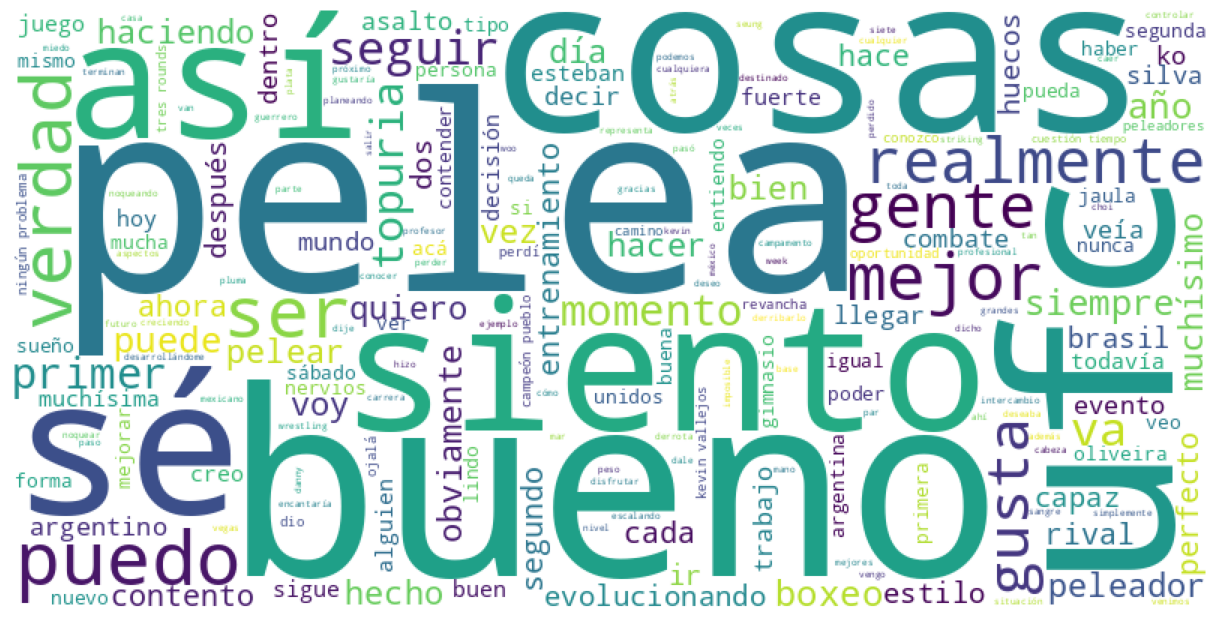

In [97]:
# Stopwords
filtradas = [p for p in tokens if p.isalpha() and p not in lista_stopwords]

# Pasar el texto a string
texto_nube = " ".join(filtradas)

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(texto_nube)

# Mostrar imagen
plt.figure(figsize=(12, 7), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

### 2.3 Usando el texto que conseguiste en el punto 1).



#### 2.3.1 Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [98]:
# Descomponer el texto en oraciones
oraciones = sent_tokenize(texto_final, language='spanish')

# Limpiar, preprocesar y armar matriz
vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=list(lista_stopwords),
    token_pattern=r'[^\d\W]+'
)

matriz = vectorizer.fit_transform(oraciones)

vocabulary = vectorizer.get_feature_names_out()
df_matriz = pd.DataFrame(matriz.toarray(), columns=vocabulary)

print("Documentos: ")
for i, oracion in enumerate(oraciones):
  print(f"Doc {i}: {oracion}")

Documentos: 
Doc 0: Kevin Vallejos, la perla argentina de UFC: "Mi sueño es ser perfecto como Topuria y el campeón del pueblo como Oliveira" Es argentino, lo apodan el 'Chino' y, a sus 23 años, ya es uno de los diamantes en bruto de la UFC.
Doc 1: Kevin Vallejos (Mar del Plata, Buenos Aires, 2001) disputa este sábado 2 de agosto su segundo combate dentro de la mejor liga del mundo de artes marciales mixtas.
Doc 2: Su debut y carta de presentación ante el gran público fue excelente: un KO en el primer asalto, marca de la casa, dejó a Seung Woo Choi dormido en la lona.
Doc 3: Un nuevo guerrero albiceleste irrumpía en la división del peso pluma de la UFC, una de las más talentosas de la compañía y en la que nuestro protagonista está destinado a grandes cosas.
Doc 4: En el primer día de la 'Fight Week' para su pelea ante Danny Silva, rival con un récord profesional de 10-1 y de orígenes mexicanos, Vallejos atiende a SPORT unos minutos para hablar sobre su próximo compromiso, su estado de f

In [99]:
# Quitar el límite de columnas y filas para que pandas imprima toda la matriz
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

print("\n Matriz Documento-Vocabulario")
print(df_matriz)


 Matriz Documento-Vocabulario
     abarca  acabaría  acercar  acoplando  acorralarlo  acostumbrados  acá  adapta  adelante  además  afuera  agosto  agregar  aguante  ah  ahora  ahí  ailín  aires  albiceleste  alejaron  alguien  algún  altura  amateur  apex  apodan  apoyando  apoyo  aprender  aprendes  aquello  argentina  argentino  argentinos  armó  artes  asalto  aspectos  aspirar  así  atiende  atrás  aunque  ayudaba  año  años  bajando  barra  base  bastante  beneficio  bien  boxea  boxear  boxeo  brasil  brothers  bruto  buen  buena  bueno  buenos  cabeza  cada  caer  cagado  cambie  cambio  camino  camp  campamento  campeón  cansado  capaz  cara  carrera  carta  cartelera  casa  casi  casualidad  categoría  cercanos  chino  choi  cima  combate  comentaristas  compara  compartir  compañeros  compañía  completo  compromiso  concretar  conecte  conexión  confiado  confío  conocer  conocidos  conozco  constancia  contacto  contar  contender  contenders  contento  contrato  controlar 


#### 2.3.2 Determina la longitud de tu vocabulario.

In [100]:
# Usar el método len para calcular la longitud del vocabulario
longitud_vocabulario = len(vocabulary)
print(f"El vocabulario tiene {longitud_vocabulario} palabras únicas.")

El vocabulario tiene 627 palabras únicas.



#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

In [101]:
# Crear un vectorizador TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=list(lista_stopwords),
    token_pattern=r'[^\d\W]+'
)

# Ajustar el vectorizador al corpus
tfidf_vectorizer.fit(oraciones)

# Obtener la representación TF-IDF
tfidf_matrix = tfidf_vectorizer.transform(oraciones)

In [102]:
vocabulary_tfidf = tfidf_vectorizer.get_feature_names_out()

df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=vocabulary_tfidf)

print(df_tfidf)

       abarca  acabaría   acercar  acoplando  acorralarlo  acostumbrados       acá    adapta  adelante    además    afuera    agosto   agregar   aguante        ah     ahora       ahí     ailín     aires  albiceleste  alejaron   alguien     algún    altura  amateur      apex    apodan  apoyando     apoyo  aprender  aprendes   aquello  argentina  argentino  argentinos      armó     artes    asalto  aspectos   aspirar       así  atiende     atrás    aunque   ayudaba       año      años   bajando     barra      base  bastante  beneficio      bien     boxea    boxear     boxeo    brasil  brothers     bruto      buen     buena     bueno    buenos    cabeza      cada      caer    cagado    cambie    cambio    camino      camp  campamento   campeón  cansado     capaz      cara   carrera     carta  cartelera      casa      casi  casualidad  categoría  cercanos     chino      choi    cima   combate  comentaristas   compara  compartir  compañeros  compañía  completo  compromiso  concretar  \
0   

In [103]:
# Calcular los pesos
pesos_tfidf = tfidf_matrix.sum(axis=0).A1

df_pesos_tfidf = pd.DataFrame({
    'palabra': vocabulary_tfidf,
    'peso_total': pesos_tfidf
})

top_palabras = df_pesos_tfidf.sort_values(by='peso_total', ascending=False).head(10)

print("10 palabras con más peso")
print(top_palabras)

10 palabras con más peso
       palabra  peso_total
61       bueno    8.920818
419      pelea    4.636088
40         así    4.229398
566         sé    4.194128
545     siento    3.954296
614     verdad    3.870903
596        ufc    3.737011
115      cosas    3.717074
494  realmente    3.356703
480      puedo    3.216879


Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

In [104]:
# Comprobar los tamaños de los documentos, vocabulario y de la matriz
documentos = tfidf_matrix.shape[0]
vocabulario = tfidf_matrix.shape[1]
tamano_total = tfidf_matrix.shape

print(f"Cantidad de Documentos: {documentos}")
print(f"Tamaño del Vocabulario: {vocabulario}")
print(f"Tamaño de la Matriz: {tamano_total}")
print(f"Total de celdas en la matriz: {documentos * vocabulario}")

Cantidad de Documentos: 173
Tamaño del Vocabulario: 627
Tamaño de la Matriz: (173, 627)
Total de celdas en la matriz: 108471


In [105]:
# Calcular el total de celdas
total_celdas = tfidf_matrix.shape[0] * tfidf_matrix.shape[1]

# Obtener las celdas que si tienen datos
celdas_con_datos = tfidf_matrix.nnz

# Calcular la diferencia para saber cuántos ceros hay
celdas_vacias = total_celdas - celdas_con_datos

# Calcular el porcentaje
porcentaje_dispersion = (celdas_vacias / total_celdas) * 100

print(f"Celdas con datos: {celdas_con_datos}")
print(f"Celdas vacías: {celdas_vacias}")
print(f"Porcentaje de dispersión: {porcentaje_dispersion:.2f}%")

Celdas con datos: 1191
Celdas vacías: 107280
Porcentaje de dispersión: 98.90%


Se puede observar un vocabulario bastante amplio y variado. Se deja ver también un porcentaje de dispersión del 98.9% lo que nos permite concluir que la gran mayoria de celdas contienen 0

# Conclusiones

Agregue aquí sus conclusiones sobre este trabajo práctico. Puede ser también parte del texto que posteará en el foro.

Con el desarrollo del trabajo práctico me di cuenta que tuve que hacer uso de varias librerias con las cuales algunas ya había trabajado y otras no. También pude sentir un acercamiento a lo que podría ser una aplicación real de todos los conocimientos que he adquirido a lo largo de la carrera.

En general, un trabajo muy entretenido y motivador a seguir con los estudios.